# MLB Hitter Breakout Predictor — Predictive Modeling

## Objective

The goal of this notebook is to predict next-season wOBA using current-season plate-discipline, contact-quality, expected-performance, and traditional performance metrics.

Models will be evaluated chronologically rather than using a random train/test split. This better represents the real-world task of using information available in one season to predict future performance.

### Model Comparison

I will compare:

1. A simple current-wOBA baseline
2. Plate-discipline features only
3. Contact-quality features only
4. Combined plate-discipline and contact-quality features
5. A full feature model including wOBA and xwOBA

The primary evaluation metric will be Mean Absolute Error (MAE), supported by RMSE and R².

In [120]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    PROCESSED_DATA_DIR / "training_data_enriched.csv"
)

print(df.shape)
df.head()

train = df[
    df["season"] <= 2023
].copy()

validation = df[
    df["season"] == 2024
].copy()

test = df[
    df["season"] == 2025
].copy()

print("Training rows:", len(train))
print("Validation rows:", len(validation))
print("Test rows:", len(test))

print()
print("Training seasons:", sorted(train["season"].unique()))
print("Validation seasons:", sorted(validation["season"].unique()))
print("Test seasons:", sorted(test["season"].unique()))

validation_baseline_pred = validation["woba"]

validation_baseline_mae = mean_absolute_error(
    validation["next_woba"],
    validation_baseline_pred
)

validation_baseline_rmse = np.sqrt(
    mean_squared_error(
        validation["next_woba"],
        validation_baseline_pred
    )
)

validation_baseline_r2 = r2_score(
    validation["next_woba"],
    validation_baseline_pred
)

print(
    "Baseline Validation MAE:",
    round(validation_baseline_mae, 4)
)

print(
    "Baseline Validation RMSE:",
    round(validation_baseline_rmse, 4)
)

print(
    "Baseline Validation R²:",
    round(validation_baseline_r2, 4)
)

PLATE_FEATURES = [
    "walk_pct",
    "strikeout_pct",
    "whiff_pct",
    "chase_pct",
]

CONTACT_FEATURES = [
    "avg_exit_velocity",
    "max_exit_velocity",
    "hard_hit_pct",
    "barrel_pct",
    "barrel_per_pa",
    "sweet_spot_pct",
    "avg_launch_angle",
]

COMBINED_FEATURES = (
    PLATE_FEATURES
    + CONTACT_FEATURES
)

FULL_FEATURES = (
    COMBINED_FEATURES
    + [
        "woba",
        "xwoba",
    ]
)

(2422, 40)
Training rows: 1822
Validation rows: 303
Test rows: 297

Training seasons: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021), np.int64(2022), np.int64(2023)]
Validation seasons: [np.int64(2024)]
Test seasons: [np.int64(2025)]
Baseline Validation MAE: 0.0295
Baseline Validation RMSE: 0.0378
Baseline Validation R²: -0.1235


In [121]:
def evaluate_regression_model(
    model_name,
    model,
    features,
    train_data,
    eval_data
):
    X_train = train_data[features]
    y_train = train_data["next_woba"]

    X_eval = eval_data[features]
    y_eval = eval_data["next_woba"]

    model.fit(
        X_train,
        y_train
    )

    predictions = model.predict(
        X_eval
    )

    mae = mean_absolute_error(
        y_eval,
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_eval,
            predictions
        )
    )

    r2 = r2_score(
        y_eval,
        predictions
    )

    return {
        "model": model_name,
        "mae": mae,
        "rmse": rmse,
        "r2": r2,
        "predictions": predictions,
        "fitted_model": model,
    }

In [122]:
def make_ridge_model(alpha=1.0):
    return Pipeline(
        steps=[
            (
                "scaler",
                StandardScaler()
            ),
            (
                "ridge",
                Ridge(alpha=alpha)
            ),
        ]
    )

In [123]:
ridge_results = []

ridge_results.append(
    evaluate_regression_model(
        "Ridge - Plate Discipline",
        make_ridge_model(),
        PLATE_FEATURES,
        train,
        validation,
    )
)

ridge_results.append(
    evaluate_regression_model(
        "Ridge - Contact Quality",
        make_ridge_model(),
        CONTACT_FEATURES,
        train,
        validation,
    )
)

ridge_results.append(
    evaluate_regression_model(
        "Ridge - Combined",
        make_ridge_model(),
        COMBINED_FEATURES,
        train,
        validation,
    )
)

ridge_results.append(
    evaluate_regression_model(
        "Ridge - Full",
        make_ridge_model(),
        FULL_FEATURES,
        train,
        validation,
    )
)

In [124]:
ridge_comparison = pd.DataFrame(
    [
        {
            "model": result["model"],
            "mae": result["mae"],
            "rmse": result["rmse"],
            "r2": result["r2"],
        }
        for result in ridge_results
    ]
)

baseline_row = pd.DataFrame(
    [
        {
            "model": "Baseline - Current wOBA",
            "mae": validation_baseline_mae,
            "rmse": validation_baseline_rmse,
            "r2": validation_baseline_r2,
        }
    ]
)

ridge_comparison = pd.concat(
    [
        baseline_row,
        ridge_comparison
    ],
    ignore_index=True
)

ridge_comparison = ridge_comparison.sort_values(
    "mae"
)

ridge_comparison

,model,mae,rmse,r2
4,Ridge - Full,0.023869,0.030357,0.274024
3,Ridge - Combined,0.024243,0.030626,0.261086
2,Ridge - Contact Quality,0.025878,0.032269,0.179697
1,Ridge - Plate Discipline,0.026828,0.033319,0.125460
0,Baseline - Current wOBA,0.029482,0.037764,-0.123471


In [125]:
ridge_comparison[
    "mae_improvement_vs_baseline"
] = (
    validation_baseline_mae
    - ridge_comparison["mae"]
)

ridge_comparison[
    "mae_improvement_pct"
] = (
    ridge_comparison[
        "mae_improvement_vs_baseline"
    ]
    / validation_baseline_mae
    * 100
)

ridge_comparison

,model,mae,rmse,r2,mae_improvement_vs_baseline,mae_improvement_pct
4,Ridge - Full,0.023869,0.030357,0.274024,0.005613,19.039053
3,Ridge - Combined,0.024243,0.030626,0.261086,0.005239,17.769119
2,Ridge - Contact Quality,0.025878,0.032269,0.179697,0.003604,12.224902
1,Ridge - Plate Discipline,0.026828,0.033319,0.125460,0.002653,9.000362
0,Baseline - Current wOBA,0.029482,0.037764,-0.123471,0.000000,0.000000


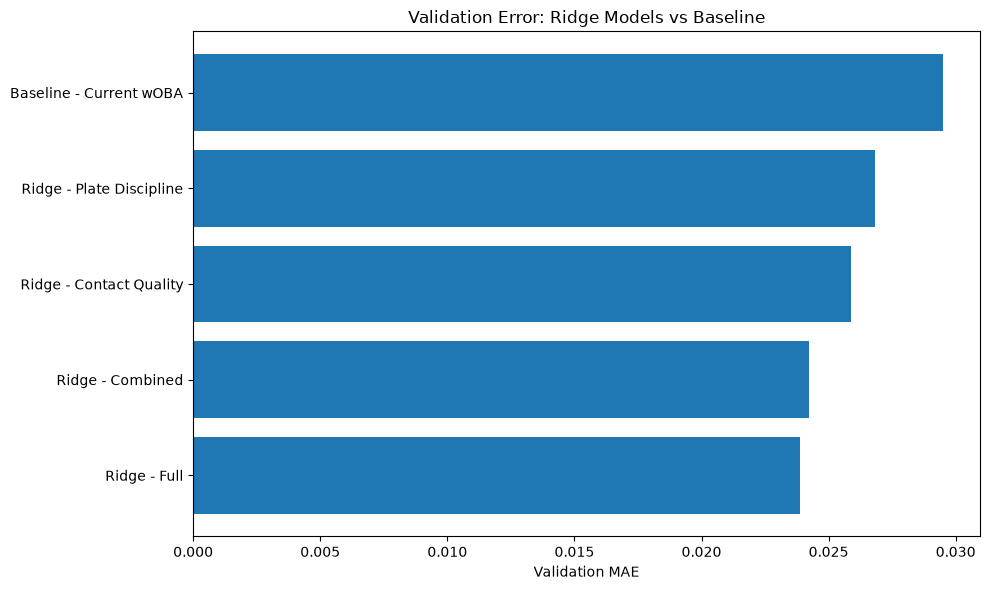

In [126]:
plot_data = (
    ridge_comparison
    .sort_values("mae")
)

plt.figure(
    figsize=(10, 6)
)

plt.barh(
    plot_data["model"],
    plot_data["mae"]
)

plt.xlabel(
    "Validation MAE"
)

plt.ylabel("")

plt.title(
    "Validation Error: Ridge Models vs Baseline"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "ridge_validation_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [127]:
best_ridge_row = (
    ridge_comparison[
        ridge_comparison["model"]
        != "Baseline - Current wOBA"
    ]
    .sort_values("mae")
    .iloc[0]
)

best_ridge_row

print(
    "Best Ridge model:",
    best_ridge_row["model"]
)

print(
    "Validation MAE:",
    round(
        best_ridge_row["mae"],
        4
    )
)

print(
    "Improvement vs baseline:",
    round(
        best_ridge_row[
            "mae_improvement_pct"
        ],
        2
    ),
    "%"
)

Best Ridge model: Ridge - Full
Validation MAE: 0.0239
Improvement vs baseline: 19.04 %


## Stronger Baseline Comparisons

Before comparing more complex machine-learning models, I tested additional simple baselines.

Because current-season xwOBA had the strongest correlation with next-season wOBA during exploratory analysis, it provides an important benchmark. A machine-learning model should ideally outperform simple predictions that can be made directly from existing statistics.

In [128]:
def calculate_metrics(y_true, predictions):
    return {
        "mae": mean_absolute_error(
            y_true,
            predictions
        ),
        "rmse": np.sqrt(
            mean_squared_error(
                y_true,
                predictions
            )
        ),
        "r2": r2_score(
            y_true,
            predictions
        ),
    }

historical_mean = (
    train["next_woba"].mean()
)

validation_mean_pred = np.full(
    len(validation),
    historical_mean
)

mean_baseline_metrics = calculate_metrics(
    validation["next_woba"],
    validation_mean_pred
)

mean_baseline_metrics

validation_xwoba_pred = (
    validation["xwoba"]
)

xwoba_baseline_metrics = calculate_metrics(
    validation["next_woba"],
    validation_xwoba_pred
)

xwoba_baseline_metrics

strong_baselines = pd.DataFrame([
    {
        "model": "Historical Mean",
        **mean_baseline_metrics
    },
    {
        "model": "Current wOBA",
        "mae": validation_baseline_mae,
        "rmse": validation_baseline_rmse,
        "r2": validation_baseline_r2,
    },
    {
        "model": "Current xwOBA",
        **xwoba_baseline_metrics
    },
])

strong_baselines.sort_values("mae")

,model,mae,rmse,r2
2,Current xwOBA,0.027231,0.034602,0.056785
0,Historical Mean,0.028691,0.035696,-0.003763
1,Current wOBA,0.029482,0.037764,-0.123471


## Random Forest Models

I next tested Random Forest regression to determine whether nonlinear relationships and interactions among plate-discipline and contact-quality metrics could improve prediction accuracy.

The initial Random Forest configuration was selected before comparing validation results so that model settings were not repeatedly adjusted to fit a single validation season.

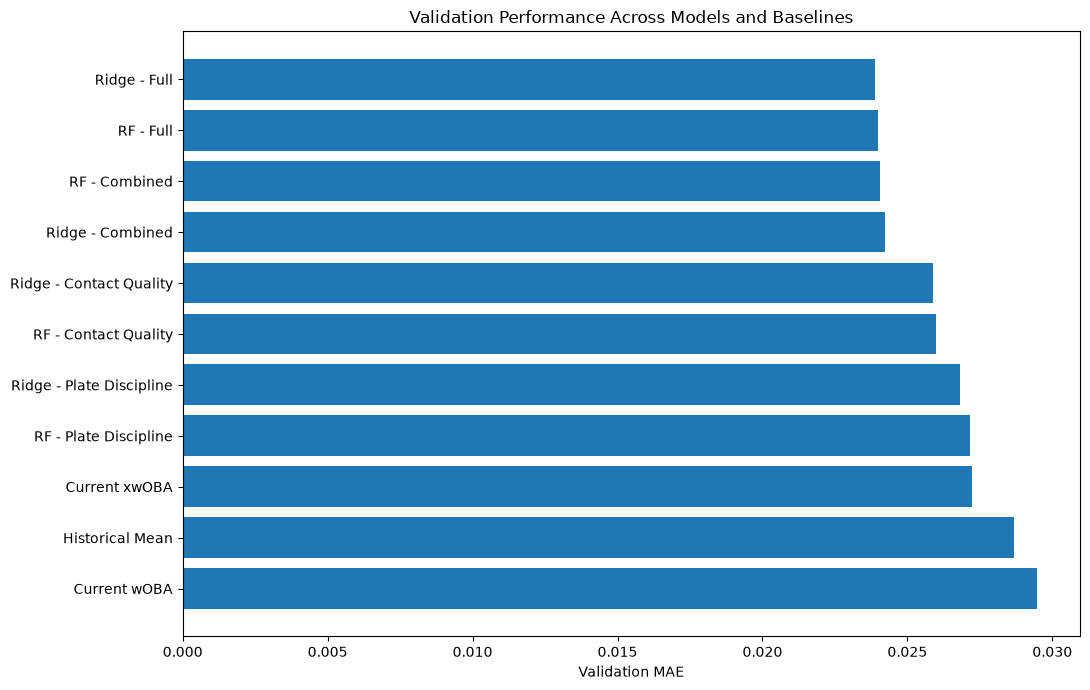

In [129]:
def make_random_forest():
    return RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=42,
        n_jobs=-1,
    )

rf_results = []

rf_results.append(
    evaluate_regression_model(
        "RF - Plate Discipline",
        make_random_forest(),
        PLATE_FEATURES,
        train,
        validation,
    )
)

rf_results.append(
    evaluate_regression_model(
        "RF - Contact Quality",
        make_random_forest(),
        CONTACT_FEATURES,
        train,
        validation,
    )
)

rf_results.append(
    evaluate_regression_model(
        "RF - Combined",
        make_random_forest(),
        COMBINED_FEATURES,
        train,
        validation,
    )
)

rf_results.append(
    evaluate_regression_model(
        "RF - Full",
        make_random_forest(),
        FULL_FEATURES,
        train,
        validation,
    )
)

rf_comparison = pd.DataFrame(
    [
        {
            "model": result["model"],
            "mae": result["mae"],
            "rmse": result["rmse"],
            "r2": result["r2"],
        }
        for result in rf_results
    ]
)

rf_comparison.sort_values("mae")

ridge_only = ridge_comparison[
    ridge_comparison["model"]
    != "Baseline - Current wOBA"
][
    ["model", "mae", "rmse", "r2"]
]

all_model_results = pd.concat(
    [
        strong_baselines,
        ridge_only,
        rf_comparison,
    ],
    ignore_index=True
)

all_model_results = (
    all_model_results
    .sort_values("mae")
    .reset_index(drop=True)
)

all_model_results

plt.figure(figsize=(11, 7))

plot_results = (
    all_model_results
    .sort_values(
        "mae",
        ascending=False
    )
)

plt.barh(
    plot_results["model"],
    plot_results["mae"]
)

plt.xlabel(
    "Validation MAE"
)

plt.ylabel("")

plt.title(
    "Validation Performance Across Models and Baselines"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "all_validation_models.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Rolling Historical Validation

A model that performs well during a single validation season may not perform consistently across different MLB seasons.

Before selecting the final model, I use expanding-window historical validation. Each validation season is predicted using only seasons that occurred before it. This provides a stronger test of model stability while keeping the final 2025-to-2026 test set completely untouched.

In [130]:
def rolling_validation(
    data,
    model_factory,
    features,
    validation_seasons
):
    results = []

    for validation_season in validation_seasons:

        train_fold = data[
            data["season"] < validation_season
        ].copy()

        validation_fold = data[
            data["season"] == validation_season
        ].copy()

        if len(train_fold) == 0 or len(validation_fold) == 0:
            continue

        model = model_factory()

        X_train = train_fold[features]
        y_train = train_fold["next_woba"]

        X_val = validation_fold[features]
        y_val = validation_fold["next_woba"]

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(
            X_val
        )

        results.append({
            "validation_season": validation_season,
            "n_hitters": len(validation_fold),
            "mae": mean_absolute_error(
                y_val,
                predictions
            ),
            "rmse": np.sqrt(
                mean_squared_error(
                    y_val,
                    predictions
                )
            ),
            "r2": r2_score(
                y_val,
                predictions
            ),
        })

    return pd.DataFrame(results)

ROLLING_VALIDATION_SEASONS = [
    2018,
    2022,
    2023,
    2024,
]

ridge_full_rolling = rolling_validation(
    df[df["season"] <= 2024],
    lambda: make_ridge_model(alpha=1.0),
    FULL_FEATURES,
    ROLLING_VALIDATION_SEASONS,
)

ridge_full_rolling

print(
    "Average Rolling MAE:",
    round(
        ridge_full_rolling["mae"].mean(),
        4
    )
)

print(
    "Average Rolling RMSE:",
    round(
        ridge_full_rolling["rmse"].mean(),
        4
    )
)

print(
    "Average Rolling R²:",
    round(
        ridge_full_rolling["r2"].mean(),
        4
    )
)

rf_full_rolling = rolling_validation(
    df[df["season"] <= 2024],
    make_random_forest,
    FULL_FEATURES,
    ROLLING_VALIDATION_SEASONS,
)

rf_full_rolling

print(
    "Average Rolling MAE:",
    round(
        rf_full_rolling["mae"].mean(),
        4
    )
)

print(
    "Average Rolling RMSE:",
    round(
        rf_full_rolling["rmse"].mean(),
        4
    )
)

print(
    "Average Rolling R²:",
    round(
        rf_full_rolling["r2"].mean(),
        4
    )
)

rolling_comparison = pd.DataFrame({
    "model": [
        "Ridge - Full",
        "Random Forest - Full"
    ],
    "avg_mae": [
        ridge_full_rolling["mae"].mean(),
        rf_full_rolling["mae"].mean()
    ],
    "avg_rmse": [
        ridge_full_rolling["rmse"].mean(),
        rf_full_rolling["rmse"].mean()
    ],
    "avg_r2": [
        ridge_full_rolling["r2"].mean(),
        rf_full_rolling["r2"].mean()
    ]
})

rolling_comparison

ridge_full_rolling

rf_full_rolling

rolling_comparison

Average Rolling MAE: 0.0258
Average Rolling RMSE: 0.0329
Average Rolling R²: 0.2645
Average Rolling MAE: 0.0258
Average Rolling RMSE: 0.033
Average Rolling R²: 0.2585


,model,avg_mae,avg_rmse,avg_r2
0,Ridge - Full,0.025782,0.032878,0.264469
1,Random Forest - Full,0.025772,0.033013,0.258548


## Final Untouched Test: 2025 → 2026

After model selection was completed using historical and 2024 validation data, I froze the final modeling approach as Ridge Regression using the full feature set.

I now retrain the selected model using all available observations through the 2024 predictor season and evaluate it once on the untouched 2025 predictor season, which represents predictions for 2026.

I do not use the final test results to select features, tune hyperparameters, or change the model.

In [131]:
final_train = df[
    df["season"] <= 2024
].copy()

final_test = df[
    df["season"] == 2025
].copy()

print("Final training rows:", len(final_train))
print("Final test rows:", len(final_test))

final_model = make_ridge_model(
    alpha=1.0
)

final_model.fit(
    final_train[FULL_FEATURES],
    final_train["next_woba"]
)

test_predictions = final_model.predict(
    final_test[FULL_FEATURES]
)

test_mae = mean_absolute_error(
    final_test["next_woba"],
    test_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(
        final_test["next_woba"],
        test_predictions
    )
)

test_r2 = r2_score(
    final_test["next_woba"],
    test_predictions
)

print(
    "Final Test MAE:",
    round(test_mae, 4)
)

print(
    "Final Test RMSE:",
    round(test_rmse, 4)
)

print(
    "Final Test R²:",
    round(test_r2, 4)
)

test_current_woba = calculate_metrics(
    final_test["next_woba"],
    final_test["woba"]
)

test_current_xwoba = calculate_metrics(
    final_test["next_woba"],
    final_test["xwoba"]
)

historical_test_mean = (
    final_train["next_woba"].mean()
)

test_historical_mean = calculate_metrics(
    final_test["next_woba"],
    np.full(
        len(final_test),
        historical_test_mean
    )
)

final_test_results = pd.DataFrame([
    {
        "model": "Ridge - Full",
        "mae": test_mae,
        "rmse": test_rmse,
        "r2": test_r2,
    },
    {
        "model": "Current xwOBA",
        **test_current_xwoba,
    },
    {
        "model": "Current wOBA",
        **test_current_woba,
    },
    {
        "model": "Historical Mean",
        **test_historical_mean,
    },
])

final_test_results = (
    final_test_results
    .sort_values("mae")
    .reset_index(drop=True)
)

final_test_results

current_woba_test_mae = (
    final_test_results.loc[
        final_test_results["model"]
        == "Current wOBA",
        "mae"
    ]
    .iloc[0]
)

test_improvement_pct = (
    (
        current_woba_test_mae
        - test_mae
    )
    / current_woba_test_mae
    * 100
)

print(
    "Final-test MAE improvement vs current wOBA:",
    round(test_improvement_pct, 2),
    "%"
)

current_xwoba_test_mae = (
    final_test_results.loc[
        final_test_results["model"]
        == "Current xwOBA",
        "mae"
    ]
    .iloc[0]
)

xwoba_improvement_pct = (
    (
        current_xwoba_test_mae
        - test_mae
    )
    / current_xwoba_test_mae
    * 100
)

print(
    "Final-test MAE improvement vs current xwOBA:",
    round(xwoba_improvement_pct, 2),
    "%"
)

test_results = final_test[
    [
        "player_id",
        "player_name",
        "season",
        "woba",
        "xwoba",
        "next_woba",
    ]
].copy()

test_results[
    "predicted_next_woba"
] = test_predictions

test_results[
    "prediction_error"
] = (
    test_results["predicted_next_woba"]
    - test_results["next_woba"]
)

test_results[
    "absolute_error"
] = (
    test_results["prediction_error"]
    .abs()
)

test_results.to_csv(
    PROCESSED_DATA_DIR
    / "final_test_predictions_2026.csv",
    index=False
)

test_results.head()

Final training rows: 2125
Final test rows: 297
Final Test MAE: 0.0248
Final Test RMSE: 0.0316
Final Test R²: 0.2307
Final-test MAE improvement vs current wOBA: 21.85 %
Final-test MAE improvement vs current xwOBA: 14.19 %


,player_id,player_name,season,woba,xwoba,next_woba,predicted_next_woba,prediction_error,absolute_error
2125,650333,"Arraez, Luis",2025,0.313,0.303,0.331,0.310669,-0.020331,0.020331
2126,680757,"Kwan, Steven",2025,0.310,0.310,0.334,0.306612,-0.027388,0.027388
2127,663538,"Hoerner, Nico",2025,0.324,0.322,0.297,0.312985,0.015985,0.015985
2128,672695,"Perdomo, Geraldo",2025,0.370,0.356,0.336,0.338994,0.002994,0.002994
2129,605141,"Betts, Mookie",2025,0.318,0.330,0.338,0.318499,-0.019501,0.019501


### Final Test Conclusion

After selecting Ridge Regression with the full feature set using historical and validation data, I evaluated the model once on the untouched 2025-to-2026 test set.

The model achieved a final Mean Absolute Error of approximately **0.0248 wOBA**, meaning that its prediction differed from a hitter's actual 2026 wOBA by about 25 points on average. The model also achieved an RMSE of approximately **0.0316** and an R² of approximately **0.231**.

Most importantly, the model reduced MAE by approximately **21.9% compared with using current-season wOBA as the prediction** and by approximately **14.2% compared with using current-season xwOBA alone**.

The final-test performance was also consistent with the model's historical rolling-validation performance. This gives me greater confidence that the model learned relationships that generalize across seasons rather than simply fitting one particular validation year.

Because the final test was not used for feature selection, model selection, or tuning, I will not make additional modeling changes based on these results. I will now retrain the finalized model using all available historical outcomes and apply it to 2026 hitter data to generate 2027 projections.

## 2027 Hitter Projections

After completing final model evaluation, I retrain the frozen Ridge Regression model using all available historical hitter-season pairs, including 2025-to-2026 outcomes.

I then apply the trained model to 2026 hitter features to estimate each player's 2027 wOBA.

These projections are model estimates rather than guarantees and do not incorporate future injuries, playing-time changes, roster changes, aging effects, or other information unavailable in the Statcast feature set.

Production training rows: 2422
Training seasons: [np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
2026 hitters available: 406
Missing required features: []
Projected 2027 breakout candidates: 0
Saved 2027 predictions.


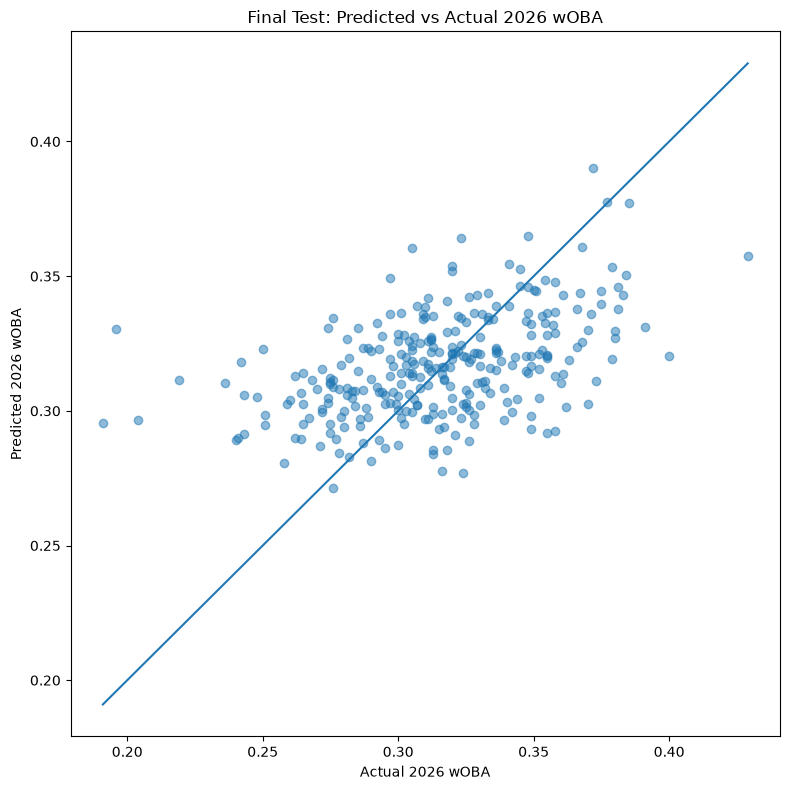

,feature,coefficient,absolute_coefficient
12,xwoba,0.013421,0.013421
2,whiff_pct,-0.007069,0.007069
4,avg_exit_velocity,0.005715,0.005715
7,barrel_pct,-0.005060,0.005060
1,strikeout_pct,0.005011,0.005011
5,max_exit_velocity,0.004813,0.004813
8,barrel_per_pa,0.004239,0.004239
6,hard_hit_pct,-0.004214,0.004214
11,woba,0.004069,0.004069
9,sweet_spot_pct,-0.002566,0.002566


In [132]:
production_train = df[
    df["season"] <= 2025
].copy()

print(
    "Production training rows:",
    len(production_train)
)

print(
    "Training seasons:",
    sorted(
        production_train["season"].unique()
    )
)

production_model = make_ridge_model(
    alpha=1.0
)

production_model.fit(
    production_train[FULL_FEATURES],
    production_train["next_woba"]
)

projection_2026 = pd.read_csv(
    PROCESSED_DATA_DIR
    / "hitter_features_2026.csv"
)

print(
    "2026 hitters available:",
    len(projection_2026)
)

projection_2026.head()

missing_features = [
    feature
    for feature in FULL_FEATURES
    if feature not in projection_2026.columns
]

print(
    "Missing required features:",
    missing_features
)

predicted_2027_woba = (
    production_model.predict(
        projection_2026[FULL_FEATURES]
    )
)

projection_2026[
    "predicted_2027_woba"
] = predicted_2027_woba

projection_2026[
    "predicted_woba_change"
] = (
    projection_2026[
        "predicted_2027_woba"
    ]
    - projection_2026["woba"]
)

projection_2026[
    [
        "player_name",
        "woba",
        "xwoba",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
].sort_values(
    "predicted_woba_change",
    ascending=False
).head(20)

BREAKOUT_THRESHOLD = 0.045

projection_2026[
    "predicted_2027_woba_pct"
] = (
    projection_2026[
        "predicted_2027_woba"
    ]
    .rank(pct=True)
)

projection_2026[
    "projected_breakout"
] = (
    (
        projection_2026[
            "predicted_woba_change"
        ]
        >= BREAKOUT_THRESHOLD
    )
    &
    (
        projection_2026[
            "predicted_2027_woba_pct"
        ]
        >= 0.60
    )
).astype(int)

breakout_candidates_2027 = (
    projection_2026[
        projection_2026[
            "projected_breakout"
        ] == 1
    ]
    .sort_values(
        "predicted_woba_change",
        ascending=False
    )
)

print(
    "Projected 2027 breakout candidates:",
    len(breakout_candidates_2027)
)

breakout_candidates_2027[
    [
        "player_name",
        "woba",
        "xwoba",
        "hard_hit_pct",
        "barrel_pct",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
].head(20)

top_2027_hitters = (
    projection_2026
    .sort_values(
        "predicted_2027_woba",
        ascending=False
    )
)

top_2027_hitters[
    [
        "player_name",
        "woba",
        "xwoba",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
].head(20)

projection_output = (
    projection_2026[
        [
            "player_id",
            "player_name",
            "season",
            "plate_appearances",
            "woba",
            "xwoba",
            "walk_pct",
            "strikeout_pct",
            "whiff_pct",
            "chase_pct",
            "avg_exit_velocity",
            "max_exit_velocity",
            "hard_hit_pct",
            "barrel_pct",
            "predicted_2027_woba",
            "predicted_woba_change",
            "predicted_2027_woba_pct",
            "projected_breakout",
        ]
    ]
    .sort_values(
        "predicted_2027_woba",
        ascending=False
    )
)

projection_output.to_csv(
    PROCESSED_DATA_DIR
    / "2027_hitter_predictions.csv",
    index=False
)

print(
    "Saved 2027 predictions."
)

plt.figure(
    figsize=(8, 8)
)

plt.scatter(
    final_test["next_woba"],
    test_predictions,
    alpha=0.5
)

minimum = min(
    final_test["next_woba"].min(),
    test_predictions.min()
)

maximum = max(
    final_test["next_woba"].max(),
    test_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum]
)

plt.xlabel(
    "Actual 2026 wOBA"
)

plt.ylabel(
    "Predicted 2026 wOBA"
)

plt.title(
    "Final Test: Predicted vs Actual 2026 wOBA"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "final_test_actual_vs_predicted.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

ridge_coefficients = (
    production_model
    .named_steps["ridge"]
    .coef_
)

coefficient_table = pd.DataFrame({
    "feature": FULL_FEATURES,
    "coefficient": ridge_coefficients,
})

coefficient_table[
    "absolute_coefficient"
] = (
    coefficient_table[
        "coefficient"
    ].abs()
)

coefficient_table = (
    coefficient_table
    .sort_values(
        "absolute_coefficient",
        ascending=False
    )
)

coefficient_table

In [133]:
# Top 20 predicted improvements

projection_2026[
    [
        "player_name",
        "woba",
        "xwoba",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
].sort_values(
    "predicted_woba_change",
    ascending=False
).head(20)

,player_name,woba,xwoba,predicted_2027_woba,predicted_woba_change
292,"Hayes, Ke'Bryan",0.191,0.287,0.288133,0.097133
405,"Polanco, Jorge",0.196,0.234,0.267581,0.071581
309,"Narváez, Carlos",0.219,0.260,0.284976,0.065976
325,"Heineman, Tyler",0.204,0.236,0.266155,0.062155
356,"Marte, Noelvi",0.242,0.237,0.291638,0.049638
255,"Vierling, Matt",0.258,0.304,0.305511,0.047511
386,"Arroyo, Edwin",0.240,0.291,0.286273,0.046273
337,"Quero, Edgar",0.251,0.282,0.297213,0.046213
290,"Friedl, TJ",0.236,0.250,0.281380,0.045380
303,"Acuña, Luisangel",0.241,0.269,0.285559,0.044559


In [134]:
# Top 20 projected hitters for 2027

projection_2026[
    [
        "player_name",
        "woba",
        "xwoba",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
].sort_values(
    "predicted_2027_woba",
    ascending=False
).head(20)

,player_name,woba,xwoba,predicted_2027_woba,predicted_woba_change
45,"Alvarez, Yordan",0.429,0.442,0.396568,-0.032432
138,"Soto, Juan",0.385,0.411,0.370796,-0.014204
135,"Wood, James",0.383,0.403,0.364654,-0.018346
58,"Alonso, Pete",0.379,0.402,0.361189,-0.017811
334,"Judge, Aaron",0.372,0.396,0.358651,-0.013349
100,"De La Cruz, Elly",0.380,0.376,0.358210,-0.021790
15,"Caminero, Junior",0.375,0.364,0.356615,-0.018385
103,"Ohtani, Shohei",0.377,0.397,0.354816,-0.022184
51,"Crow-Armstrong, Pete",0.400,0.374,0.353892,-0.046108
153,"Contreras, Willson",0.391,0.376,0.352416,-0.038584


In [135]:
# Distribution of predicted improvement

projection_2026[
    "predicted_woba_change"
].describe(
    percentiles=[
        0.50,
        0.75,
        0.90,
        0.95,
        0.99
    ]
)

count    406.000000
mean      -0.001708
std        0.022570
min       -0.055127
50%       -0.001091
75%        0.012943
90%        0.024983
95%        0.035459
99%        0.049531
max        0.097133
Name: predicted_woba_change, dtype: float64

In [136]:
breakout_watchlist_2027 = (
    projection_2026
    .sort_values(
        "predicted_woba_change",
        ascending=False
    )
    .head(20)
    .copy()
)

breakout_watchlist_2027[
    "improvement_rank"
] = range(
    1,
    len(breakout_watchlist_2027) + 1
)

breakout_watchlist_2027[
    [
        "improvement_rank",
        "player_name",
        "woba",
        "xwoba",
        "predicted_2027_woba",
        "predicted_woba_change",
    ]
]

breakout_watchlist_2027.to_csv(
    PROCESSED_DATA_DIR
    / "2027_breakout_watchlist.csv",
    index=False
)

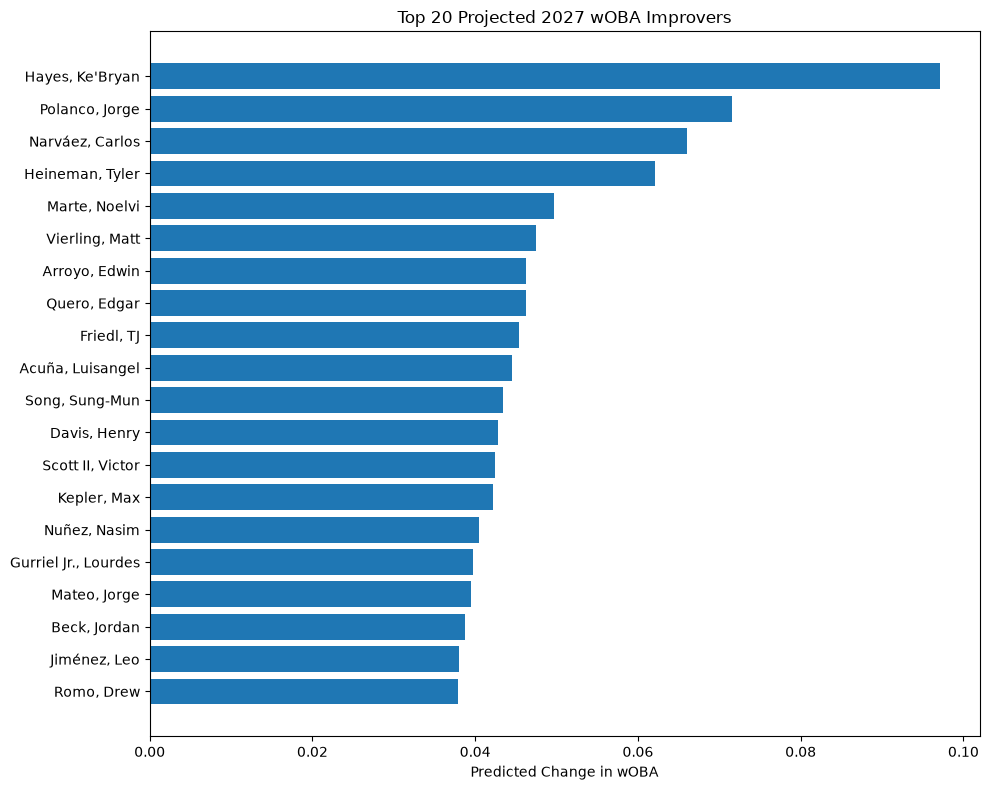

In [137]:
watchlist_plot = (
    breakout_watchlist_2027
    .sort_values(
        "predicted_woba_change"
    )
)

plt.figure(figsize=(10, 8))

plt.barh(
    watchlist_plot["player_name"],
    watchlist_plot[
        "predicted_woba_change"
    ]
)

plt.xlabel(
    "Predicted Change in wOBA"
)

plt.ylabel("")

plt.title(
    "Top 20 Projected 2027 wOBA Improvers"
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "2027_breakout_watchlist.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Modeling and 2027 Projection Conclusions

### Model Selection

I compared simple performance baselines, Ridge Regression models, and Random Forest models using chronological validation rather than randomly splitting hitter-seasons.

Ridge Regression using the full feature set ultimately provided the best balance of predictive performance, stability, and interpretability. During rolling historical validation, its performance was essentially tied with Random Forest while producing slightly better RMSE and R² results overall.

Because Ridge Regression was simpler and easier to interpret while maintaining comparable accuracy, I selected it as my final model before evaluating the untouched test set.

### Final Test Performance

I evaluated the frozen model once using 2025 hitter statistics to predict 2026 wOBA.

The model achieved:

- MAE of approximately **0.0248 wOBA**
- RMSE of approximately **0.0316**
- R² of approximately **0.231**

The model reduced Mean Absolute Error by approximately **21.9% compared with using current-season wOBA alone** and by approximately **14.2% compared with using current-season xwOBA alone**.

The final-test MAE was also very similar to the model's historical rolling-validation error, which increased my confidence that its performance generalized across seasons rather than being specific to one validation year.

### 2027 Projections

After final evaluation, I retrained the frozen Ridge model using all available historical hitter-season outcomes and applied it to 2026 hitter data to generate 2027 wOBA projections.

I created two separate outputs from these projections.

The first ranks hitters by predicted 2027 wOBA and represents the players the model expects to be the strongest overall offensive performers.

The second ranks hitters by predicted year-over-year improvement and serves as a **2027 Breakout Watchlist**.

I intentionally distinguish this watchlist from my historical breakout classification. The historical definition required an actual wOBA improvement of approximately 0.045 or greater while also reaching a sufficiently strong offensive level. Point predictions from a regularized regression model are naturally less extreme than actual season-to-season outcomes, so I do not lower the historical threshold simply to generate additional projected breakouts.

Instead, the watchlist identifies the hitters whose 2027 performance the model expects to improve the most relative to their 2026 results.

### Final Takeaway

My results suggest that current offensive performance contains meaningful information about future performance, but Statcast contact-quality and plate-discipline metrics add additional predictive value.

Contact-quality measures were particularly useful throughout the project, while xwOBA consistently provided strong information about future performance. Combining these variables allowed the final model to outperform both current wOBA and current xwOBA as standalone predictions on the untouched final test set.

The project also showed an important difference between predicting who will be **good** and predicting who will **improve the most**. Elite current hitters were often projected to remain elite without necessarily making large year-over-year gains, while the largest projected improvements frequently belonged to hitters coming from weaker current-season results.

Overall, I was able to build an end-to-end data science workflow that collected and cleaned multi-season MLB data, engineered features, tested baseball hypotheses, compared multiple predictive models using chronological validation, evaluated a frozen model on unseen future-season data, and generated 2027 hitter projections.